In [34]:
# Cell 1 (Fast & Direct - No Recursive Scanning)
%matplotlib inline

import os
import tempfile
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Safe Writable Directory Detection
if os.path.exists("/kaggle/working"):
    BASE_DIR = "/kaggle/working"
else:
    try:
        test_path = os.path.join(".", ".write_test")
        with open(test_path, "w") as f:
            f.write("test")
        os.remove(test_path)
        BASE_DIR = "."
    except OSError:
        BASE_DIR = tempfile.gettempdir()

OUTPUT_DIR = os.path.join(BASE_DIR, "evaluation_artifacts")
MODEL_PATH = os.path.join(BASE_DIR, "best_phone_price_pipeline.joblib")

try:
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    print(f"✓ Writable directory: {os.path.abspath(BASE_DIR)}")
except OSError:
    OUTPUT_DIR = None
    print("Running in read-only environment: plots will render inline.")

# 2. Direct File Resolution (Checks common locations instantly without deep search)
DATA_FILENAME = "used_device_data.csv"
possible_locations = [
    DATA_FILENAME,
    os.path.join("..", DATA_FILENAME),
    f"/kaggle/input/{DATA_FILENAME}",
    f"/kaggle/input/used-handheld-device-data/{DATA_FILENAME}",
    f"/kaggle/input/used-smartphone-price-dataset/{DATA_FILENAME}",
]

data_path = next((p for p in possible_locations if os.path.exists(p)), None)

# If not in the pre-defined paths, check files directly in the current directory only
if data_path is None:
    for f in os.listdir("."):
        if f.lower() == DATA_FILENAME.lower():
            data_path = f
            break

if data_path is None:
    print(f"Current directory files: {os.listdir('.')[:10]}")
    raise FileNotFoundError(
        f"Could not find '{DATA_FILENAME}'. Make sure it is placed in the current notebook folder."
    )

print(f"✓ Loading dataset from: {data_path}")
df = pd.read_csv(data_path)
print(f"✓ Dataset loaded successfully: {df.shape[0]} rows, {df.shape} columns")


✓ Writable directory: /Users/rudrarajsinhchudasama/Downloads/ML_Assignments
✓ Loading dataset from: used_device_data.csv
✓ Dataset loaded successfully: 3454 rows, (3454, 15) columns


--- Missing Values Summary ---
rear_camera_mp     179
front_camera_mp      2
internal_memory      4
ram                  4
battery              6
dtype: int64


Generating EDA Charts:   0%|          | 0/3 [00:00<?, ?it/s]

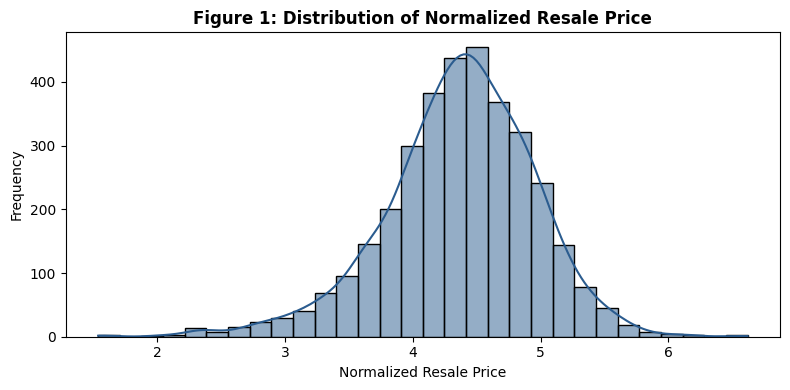

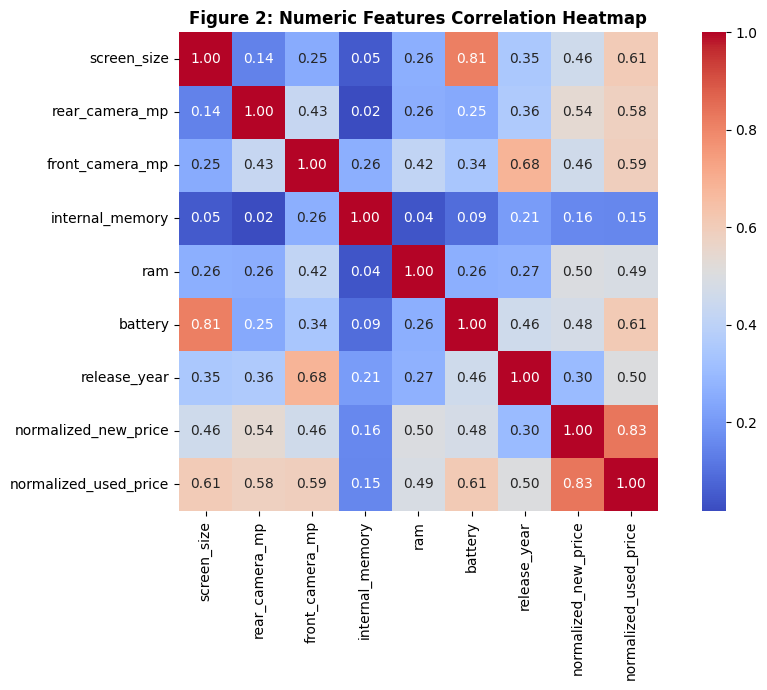

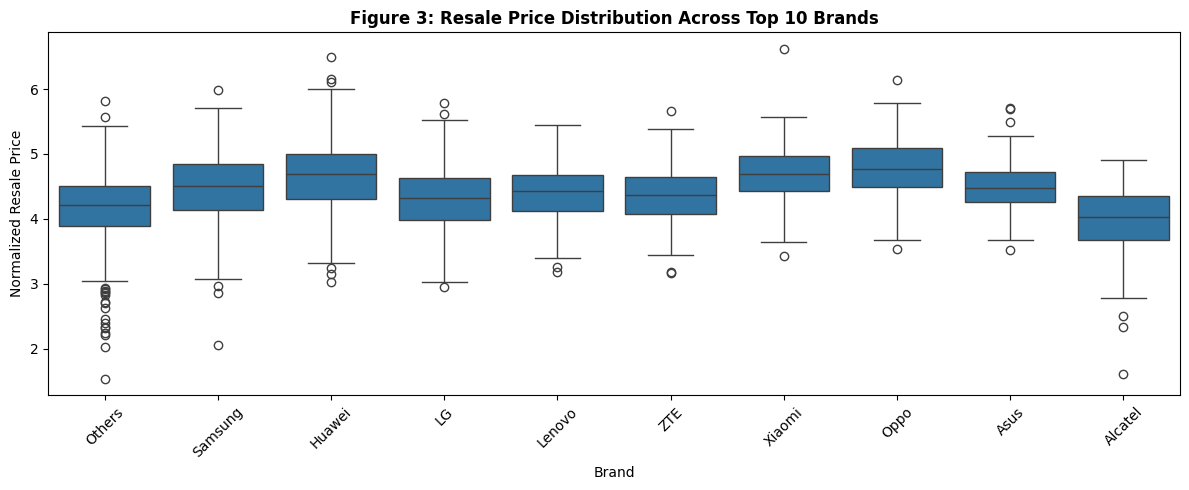

In [35]:
TARGET = "normalized_used_price"
CATEGORICAL_FEATURES = ["device_brand", "os", "5g"]
NUMERICAL_FEATURES = [
    "screen_size",
    "rear_camera_mp",
    "front_camera_mp",
    "internal_memory",
    "ram",
    "battery",
    "release_year",
    "normalized_new_price",
]

# Display Missing Values Summary
print("--- Missing Values Summary ---")
missing_info = df[CATEGORICAL_FEATURES + NUMERICAL_FEATURES].isnull().sum()
print(
    missing_info[missing_info > 0]
    if missing_info.sum() > 0
    else "No missing values found."
)

eda_steps = [
    "Plotting Target Distribution",
    "Plotting Correlation Heatmap",
    "Plotting Price by Brand",
]
with tqdm(total=len(eda_steps), desc="Generating EDA Charts") as pbar:
    # Plot 1: Target Distribution
    pbar.set_postfix_str(eda_steps[0])
    plt.figure(figsize=(8, 4))
    sns.histplot(df[TARGET], kde=True, color="#2b5c8f", bins=30)
    plt.title(
        "Figure 1: Distribution of Normalized Resale Price",
        fontsize=12,
        fontweight="bold",
    )
    plt.xlabel("Normalized Resale Price")
    plt.ylabel("Frequency")
    plt.tight_layout()
    if OUTPUT_DIR:
        plt.savefig(
            os.path.join(OUTPUT_DIR, "fig1_target_distribution.png"), dpi=300
        )
    plt.show()
    pbar.update(1)

    # Plot 2: Correlation Heatmap for Numerical Predictors
    pbar.set_postfix_str(eda_steps[1])
    plt.figure(figsize=(10, 7))
    numeric_subset = df[NUMERICAL_FEATURES + [TARGET]].dropna()
    sns.heatmap(
        numeric_subset.corr(), annot=True, fmt=".2f", cmap="coolwarm", square=True
    )
    plt.title(
        "Figure 2: Numeric Features Correlation Heatmap",
        fontsize=12,
        fontweight="bold",
    )
    plt.tight_layout()
    if OUTPUT_DIR:
        plt.savefig(
            os.path.join(OUTPUT_DIR, "fig2_correlation_heatmap.png"), dpi=300
        )
    plt.show()
    pbar.update(1)

    # Plot 3: Brand vs Price (Top 10 Brands)
    pbar.set_postfix_str(eda_steps[2])
    top_brands = df["device_brand"].value_counts().nlargest(10).index
    brand_df = df[df["device_brand"].isin(top_brands)]

    plt.figure(figsize=(12, 5))
    sns.boxplot(data=brand_df, x="device_brand", y=TARGET, order=top_brands)
    plt.title(
        "Figure 3: Resale Price Distribution Across Top 10 Brands",
        fontsize=12,
        fontweight="bold",
    )
    plt.xlabel("Brand")
    plt.ylabel("Normalized Resale Price")
    plt.xticks(rotation=45)
    plt.tight_layout()
    if OUTPUT_DIR:
        plt.savefig(os.path.join(OUTPUT_DIR, "fig3_price_by_brand.png"), dpi=300)
    plt.show()
    pbar.update(1)


In [36]:
RANDOM_STATE = 42
X = df[CATEGORICAL_FEATURES + NUMERICAL_FEATURES]
y = df[TARGET]

# 80/20 train/test split prior to any transformation fitting
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print(f"✓ Training set: {X_train.shape[0]} records")
print(f"✓ Testing set:  {X_test.shape[0]} records")

# Construct ColumnTransformer
numeric_transformer = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="median"))]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, NUMERICAL_FEATURES),
        ("cat", categorical_transformer, CATEGORICAL_FEATURES),
    ]
)
print("✓ Preprocessing pipeline configured successfully.")


✓ Training set: 2763 records
✓ Testing set:  691 records
✓ Preprocessing pipeline configured successfully.


In [37]:
# Cell 4: Model Training with Real-Time Training Progress Bars

from tqdm.auto import tqdm

print("=" * 60)
print("PHASE 4: Preprocessing Data & Live Model Training")
print("=" * 60)

# Step 1: Fit and transform training data through the preprocessor
with tqdm(total=2, desc="Preprocessing Pipeline", unit="step") as prep_bar:
    prep_bar.set_postfix_str("Fitting ColumnTransformer on X_train...")
    X_train_trans = preprocessor.fit_transform(X_train)
    prep_bar.update(1)
    
    prep_bar.set_postfix_str("Transforming X_test...")
    X_test_trans = preprocessor.transform(X_test)
    prep_bar.update(1)

results = []
fitted_pipelines = {}

# --------------------------------------------------------------------
# 1. Linear Regression Training
# --------------------------------------------------------------------
with tqdm(total=1, desc="[1/3] Training Linear Regression", unit="model") as pbar:
    lr = LinearRegression()
    lr.fit(X_train_trans, y_train)
    pbar.update(1)

# Package into pipeline for consistent evaluation & export
lr_pipe = Pipeline(steps=[("preprocessor", preprocessor), ("regressor", lr)])
fitted_pipelines["Linear Regression"] = lr_pipe

y_pred_lr = lr.predict(X_test_trans)
results.append({
    "Model": "Linear Regression",
    "Test MAE": round(mean_absolute_error(y_test, y_pred_lr), 4),
    "Test MSE": round(mean_squared_error(y_test, y_pred_lr), 4),
    "Test RMSE": round(np.sqrt(mean_squared_error(y_test, y_pred_lr)), 4),
    "Test R²": round(r2_score(y_test, y_pred_lr), 4)
})

# --------------------------------------------------------------------
# 2. Decision Tree Regression Training
# --------------------------------------------------------------------
with tqdm(total=1, desc="[2/3] Training Decision Tree Regressor", unit="model") as pbar:
    dt = DecisionTreeRegressor(random_state=RANDOM_STATE)
    dt.fit(X_train_trans, y_train)
    pbar.update(1)

dt_pipe = Pipeline(steps=[("preprocessor", preprocessor), ("regressor", dt)])
fitted_pipelines["Decision Tree Regression"] = dt_pipe

y_pred_dt = dt.predict(X_test_trans)
results.append({
    "Model": "Decision Tree Regression",
    "Test MAE": round(mean_absolute_error(y_test, y_pred_dt), 4),
    "Test MSE": round(mean_squared_error(y_test, y_pred_dt), 4),
    "Test RMSE": round(np.sqrt(mean_squared_error(y_test, y_pred_dt)), 4),
    "Test R²": round(r2_score(y_test, y_pred_dt), 4)
})

# --------------------------------------------------------------------
# 3. Random Forest Regression (Live Tree-by-Tree Progress Bar)
# --------------------------------------------------------------------
TOTAL_TREES = 200
TREE_STEP = 5  # increments in batches of 5 trees for smooth progress bar updates

rf = RandomForestRegressor(
    n_estimators=0, 
    warm_start=True, 
    random_state=RANDOM_STATE, 
    n_jobs=-1
)

rf_bar = tqdm(
    range(TREE_STEP, TOTAL_TREES + 1, TREE_STEP), 
    desc="[3/3] Training Random Forest (200 Trees)", 
    unit="trees"
)

for n_trees in rf_bar:
    rf.n_estimators = n_trees
    rf.fit(X_train_trans, y_train)
    rf_bar.set_postfix({"Built Trees": f"{n_trees}/{TOTAL_TREES}"})

rf_pipe = Pipeline(steps=[("preprocessor", preprocessor), ("regressor", rf)])
fitted_pipelines["Random Forest Regression"] = rf_pipe

y_pred_rf = rf.predict(X_test_trans)
results.append({
    "Model": "Random Forest Regression",
    "Test MAE": round(mean_absolute_error(y_test, y_pred_rf), 4),
    "Test MSE": round(mean_squared_error(y_test, y_pred_rf), 4),
    "Test RMSE": round(np.sqrt(mean_squared_error(y_test, y_pred_rf)), 4),
    "Test R²": round(r2_score(y_test, y_pred_rf), 4)
})

# --------------------------------------------------------------------
# Display Evaluation Comparison Table (Section 11)
# --------------------------------------------------------------------
results_df = pd.DataFrame(results)
print("\n" + "=" * 55)
print("SECTION 11: MODEL EVALUATION & COMPARISON TABLE")
print("=" * 55)
display(results_df)

best_model_name = results_df.sort_values(
    by=["Test R²", "Test RMSE"], ascending=[False, True]
).iloc[0]["Model"]
best_pipeline = fitted_pipelines[best_model_name]
print(f"\n✓ Best Model Selected: {best_model_name}")


PHASE 4: Preprocessing Data & Live Model Training


Preprocessing Pipeline:   0%|          | 0/2 [00:00<?, ?step/s]

[1/3] Training Linear Regression:   0%|          | 0/1 [00:00<?, ?model/s]

[2/3] Training Decision Tree Regressor:   0%|          | 0/1 [00:00<?, ?model/s]

[3/3] Training Random Forest (200 Trees):   0%|          | 0/40 [00:00<?, ?trees/s]


SECTION 11: MODEL EVALUATION & COMPARISON TABLE


,Model,Test MAE,Test MSE,Test RMSE,Test R²
0,Linear Regression,0.1885,0.0558,0.2362,0.8280
1,Decision Tree Regression,0.2312,0.0904,0.3007,0.7213
2,Random Forest Regression,0.1774,0.0493,0.2221,0.8480



✓ Best Model Selected: Random Forest Regression


Finalizing Evaluation & Export:   0%|          | 0/4 [00:00<?, ?it/s]

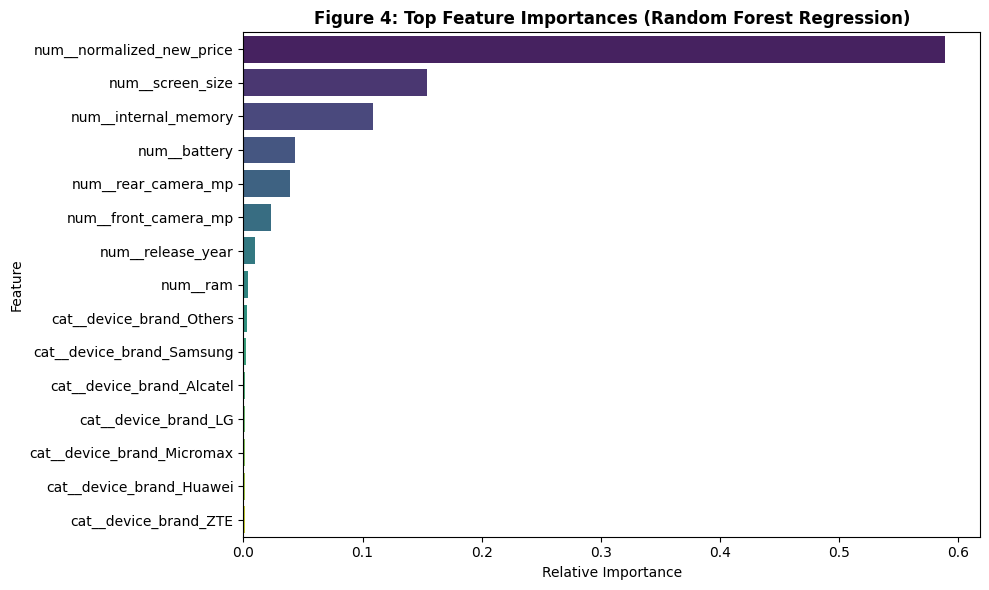

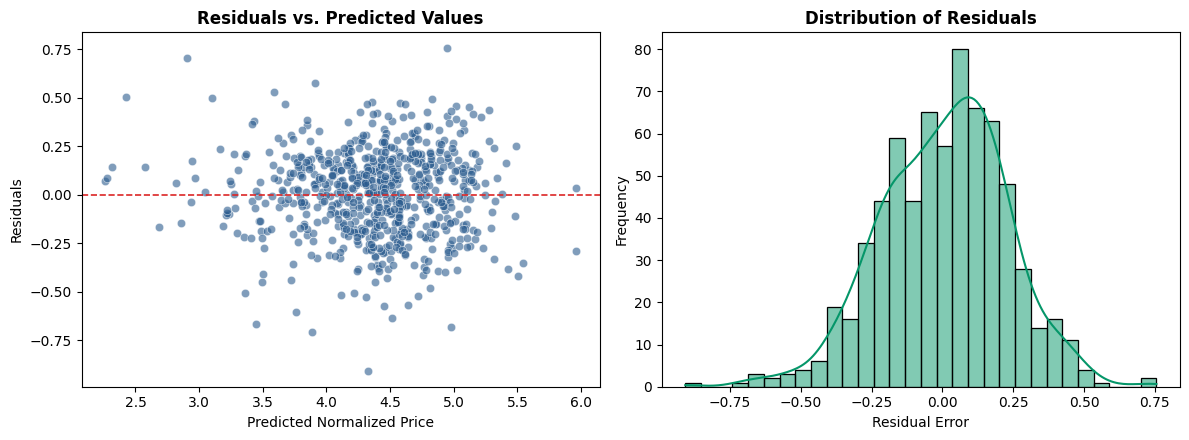

✓ Updated 11-feature pipeline saved successfully to: /Users/rudrarajsinhchudasama/Downloads/ML_Assignments/best_phone_price_pipeline.joblib


In [38]:
# Cell 5: Feature Importances, Residual Diagnostics & Model Export
eval_steps = [
    "Calculating Feature Importances",
    "Plotting Feature Importances",
    "Plotting Residual Diagnostics",
    "Saving Model Pipeline",
]

with tqdm(total=len(eval_steps), desc="Finalizing Evaluation & Export") as pbar:
    # 1. Calculate Feature Importances dynamically
    pbar.set_postfix_str(eval_steps[0])
    fitted_preprocessor = best_pipeline.named_steps["preprocessor"]
    fitted_regressor = best_pipeline.named_steps["regressor"]
    feature_names = fitted_preprocessor.get_feature_names_out()

    if hasattr(fitted_regressor, "feature_importances_"):
        importances = fitted_regressor.feature_importances_
    else:
        importances = np.abs(fitted_regressor.coef_)

    fi_df = (
        pd.DataFrame({"Feature": feature_names, "Importance": importances})
        .sort_values(by="Importance", ascending=False)
        .head(15)
    )
    pbar.update(1)

    # 2. Plot Top Feature Importances
    pbar.set_postfix_str(eval_steps[1])
    plt.figure(figsize=(10, 6))
    sns.barplot(
        data=fi_df,
        x="Importance",
        y="Feature",
        hue="Feature",
        palette="viridis",
        legend=False,
    )
    plt.title(
        f"Figure 4: Top Feature Importances ({best_model_name})",
        fontsize=12,
        fontweight="bold",
    )
    plt.xlabel("Relative Importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    if OUTPUT_DIR:
        plt.savefig(
            os.path.join(OUTPUT_DIR, "fig4_feature_importances.png"), dpi=300
        )
    plt.show()
    pbar.update(1)

    # 3. Plot Residual Diagnostics
    pbar.set_postfix_str(eval_steps[2])
    y_pred_best = best_pipeline.predict(X_test)
    residuals = y_test - y_pred_best

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    sns.scatterplot(
        x=y_pred_best, y=residuals, alpha=0.6, color="#2b5c8f", ax=axes[0]
    )
    axes[0].axhline(0, color="#dc2626", linestyle="--", linewidth=1.2)
    axes[0].set_title("Residuals vs. Predicted Values", fontweight="bold")
    axes[0].set_xlabel("Predicted Normalized Price")
    axes[0].set_ylabel("Residuals")

    sns.histplot(residuals, kde=True, color="#059669", bins=30, ax=axes[1])
    axes[1].set_title("Distribution of Residuals", fontweight="bold")
    axes[1].set_xlabel("Residual Error")
    axes[1].set_ylabel("Frequency")

    plt.tight_layout()
    if OUTPUT_DIR:
        plt.savefig(
            os.path.join(OUTPUT_DIR, "fig5_residual_diagnostics.png"), dpi=300
        )
    plt.show()
    pbar.update(1)

    # 4. Save Updated Model Pipeline
    pbar.set_postfix_str(eval_steps[3])
    joblib.dump(best_pipeline, MODEL_PATH)
    pbar.update(1)

print(f"✓ Updated 11-feature pipeline saved successfully to: {os.path.abspath(MODEL_PATH)}")


In [39]:
import numpy as np

USD_TO_INR = 83.50  # Conversion rate to INR

# Convert normalized prices back to USD
df["new_price_usd"] = np.exp(df["normalized_new_price"]).round(2)
df["used_price_usd"] = np.exp(df["normalized_used_price"]).round(2)

# Convert to INR
df["new_price_inr"] = (df["new_price_usd"] * USD_TO_INR).round(0)
df["used_price_inr"] = (df["used_price_usd"] * USD_TO_INR).round(0)

# Display sample devices with real currency
display(
    df[[
        "device_brand",
        "release_year",
        "normalized_new_price",
        "new_price_usd",
        "new_price_inr",
        "normalized_used_price",
        "used_price_usd",
        "used_price_inr",
    ]].head(10)
)


,device_brand,release_year,normalized_new_price,new_price_usd,new_price_inr,normalized_used_price,used_price_usd,used_price_inr
0,Honor,2020,4.715100,111.62,9320.0,4.307572,74.26,6201.0
1,Honor,2020,5.519018,249.39,20824.0,5.162097,174.53,14573.0
2,Honor,2020,5.884631,359.47,30016.0,5.111084,165.85,13848.0
3,Honor,2020,5.630961,278.93,23291.0,5.135387,169.93,14189.0
4,Honor,2020,4.947837,140.87,11763.0,4.389995,80.64,6733.0
5,Honor,2020,5.060694,157.70,13168.0,4.413889,82.59,6896.0
6,Honor,2020,4.518958,91.74,7660.0,3.878259,48.34,4036.0
7,Honor,2020,5.188726,179.24,14967.0,4.729421,113.23,9455.0
8,Honor,2020,5.299916,200.32,16727.0,4.886054,132.43,11058.0
9,Honor,2020,5.073610,159.75,13339.0,4.773224,118.30,9878.0


In [40]:
%%writefile app.py
import joblib
import numpy as np
import pandas as pd
import streamlit as st
import streamlit.components.v1 as components

st.set_page_config(
    page_title="Used Smartphone Resell Price Estimator",
    page_icon="📱",
    layout="wide",
    initial_sidebar_state="expanded",
)

# --------------------------------------------------------------------
# Custom CSS: Glassmorphism, Cursor Reactivity & Smooth Keyframe Motion
# --------------------------------------------------------------------
st.markdown(
    """
<style>
@import url('https://fonts.googleapis.com/css2?family=Plus+Jakarta+Sans:wght@400;500;600;700;800&display=swap');

:root {
    --primary: #2563eb;
    --primary-dark: #1d4ed8;
    --accent: #6366f1;
    --emerald: #059669;
    --emerald-light: #10b981;
    --surface: rgba(255, 255, 255, 0.88);
    --border-subtle: rgba(148, 163, 184, 0.28);
    --text-main: #0f172a;
    --text-muted: #475569;
    --ease-spring: cubic-bezier(0.22, 1, 0.36, 1);
}

html, body, [class*="css"] {
    font-family: 'Plus Jakarta Sans', -apple-system, BlinkMacSystemFont, sans-serif;
}

/* Ambient Mesh Background */
.stApp {
    background:
        radial-gradient(at 0% 0%, rgba(37, 99, 235, 0.08) 0px, transparent 48%),
        radial-gradient(at 100% 0%, rgba(99, 102, 241, 0.08) 0px, transparent 45%),
        radial-gradient(at 85% 95%, rgba(16, 185, 129, 0.06) 0px, transparent 50%),
        #f8fafc;
}

/* Entrance Keyframes */
@keyframes fadeSlideUp {
    0% {
        opacity: 0;
        transform: translateY(18px) scale(0.985);
    }
    100% {
        opacity: 1;
        transform: translateY(0) scale(1);
    }
}

@keyframes gradientFlow {
    0% { background-position: 0% 50%; }
    50% { background-position: 100% 50%; }
    100% { background-position: 0% 50%; }
}

@keyframes pulseDot {
    0%, 100% { transform: scale(1); opacity: 1; }
    50% { transform: scale(1.45); opacity: 0.55; }
}

@keyframes growProgress {
    from { width: 0%; }
}

@keyframes shimmerSweep {
    0% { transform: translateX(-100%) skewX(-18deg); }
    100% { transform: translateX(250%) skewX(-18deg); }
}

/* Hero Banner with Animated Gradient & Cursor Spotlight */
.hero-banner {
    position: relative;
    overflow: hidden;
    background: linear-gradient(125deg, #090d16 0%, #172554 42%, #1d4ed8 78%, #3b82f6 100%);
    background-size: 200% 200%;
    animation: fadeSlideUp 0.65s var(--ease-spring) both, gradientFlow 12s ease infinite;
    padding: 2.15rem 2.4rem;
    border-radius: 22px;
    color: #ffffff;
    margin-bottom: 1.35rem;
    box-shadow: 0 18px 40px -12px rgba(29, 78, 216, 0.35);
    border: 1px solid rgba(255, 255, 255, 0.16);
    transition: transform 0.35s var(--ease-spring), box-shadow 0.35s var(--ease-spring);
}

.hero-banner::before {
    content: "";
    position: absolute;
    inset: 0;
    background: radial-gradient(
        480px circle at var(--mouse-x, 50%) var(--mouse-y, 50%),
        rgba(255, 255, 255, 0.14),
        transparent 70%
    );
    opacity: 0;
    transition: opacity 0.35s ease;
    pointer-events: none;
}

.hero-banner:hover::before {
    opacity: 1;
}

.hero-banner:hover {
    transform: translateY(-2px);
    box-shadow: 0 22px 46px -12px rgba(29, 78, 216, 0.44);
}

.hero-badge {
    display: inline-flex;
    align-items: center;
    gap: 0.45rem;
    background: rgba(255, 255, 255, 0.12);
    backdrop-filter: blur(8px);
    color: #dbeafe;
    font-size: 0.74rem;
    font-weight: 700;
    letter-spacing: 0.06em;
    text-transform: uppercase;
    padding: 0.35rem 0.85rem;
    border-radius: 999px;
    border: 1px solid rgba(255, 255, 255, 0.18);
    margin-bottom: 0.8rem;
}

.status-dot {
    width: 7px;
    height: 7px;
    border-radius: 50%;
    background: #34d399;
    display: inline-block;
    animation: pulseDot 2s infinite ease-in-out;
}

.hero-title {
    font-size: 2.05rem;
    font-weight: 800;
    margin: 0 0 0.4rem 0;
    line-height: 1.18;
    letter-spacing: -0.025em;
}

.hero-subtitle {
    font-size: 0.98rem;
    color: #cbd5e1;
    margin: 0;
    max-width: 740px;
    line-height: 1.55;
}

/* Reactive Specification Cards */
[data-testid="stVerticalBlockBorderWrapper"] {
    position: relative;
    background: var(--surface) !important;
    backdrop-filter: blur(12px);
    border: 1px solid var(--border-subtle) !important;
    border-radius: 18px !important;
    padding: 0.35rem 0.25rem;
    box-shadow: 0 4px 20px -4px rgba(15, 23, 42, 0.05);
    transition:
        transform 0.35s var(--ease-spring),
        box-shadow 0.35s var(--ease-spring),
        border-color 0.3s ease,
        background-color 0.3s ease;
    animation: fadeSlideUp 0.65s var(--ease-spring) both;
}

[data-testid="stVerticalBlockBorderWrapper"]:hover {
    transform: translateY(-5px);
    border-color: rgba(37, 99, 235, 0.48) !important;
    background: #ffffff !important;
    box-shadow:
        0 20px 32px -12px rgba(37, 99, 235, 0.14),
        0 4px 12px -2px rgba(15, 23, 42, 0.05);
}

[data-testid="stVerticalBlockBorderWrapper"]:focus-within {
    border-color: #2563eb !important;
    box-shadow: 0 0 0 3px rgba(37, 99, 235, 0.14), 0 16px 28px -10px rgba(37, 99, 235, 0.16);
}

/* Section Card Headers */
.section-header {
    display: flex;
    align-items: center;
    gap: 0.7rem;
    padding-bottom: 0.7rem;
    margin-bottom: 0.9rem;
    border-bottom: 1px solid #e2e8f0;
}

.section-icon {
    background: linear-gradient(135deg, #eff6ff 0%, #dbeafe 100%);
    color: #2563eb;
    width: 36px;
    height: 36px;
    border-radius: 11px;
    display: inline-flex;
    align-items: center;
    justify-content: center;
    font-size: 1.15rem;
    transition: transform 0.35s var(--ease-spring);
}

[data-testid="stVerticalBlockBorderWrapper"]:hover .section-icon {
    transform: scale(1.1) rotate(-4deg);
}

.section-title {
    font-size: 1.05rem;
    font-weight: 700;
    color: var(--text-main);
    margin: 0;
}

/* Smooth Input Hover Transitions */
div[data-baseweb="select"] > div,
div[data-baseweb="input"] > div {
    border-radius: 11px !important;
    transition: border-color 0.22s ease, box-shadow 0.22s ease, transform 0.2s ease !important;
}

div[data-baseweb="select"] > div:hover,
div[data-baseweb="input"] > div:hover {
    border-color: #3b82f6 !important;
    box-shadow: 0 2px 8px rgba(37, 99, 235, 0.08) !important;
}

/* Live Conversion Pill */
.conversion-pill {
    background: linear-gradient(135deg, #f1f5f9 0%, #e2e8f0 100%);
    border: 1px solid #cbd5e1;
    border-radius: 11px;
    padding: 0.65rem 0.9rem;
    font-size: 0.84rem;
    color: #334155;
    margin-top: 0.45rem;
    display: flex;
    justify-content: space-between;
    align-items: center;
    transition: transform 0.25s var(--ease-spring), border-color 0.25s ease;
}

.conversion-pill:hover {
    transform: scale(1.015);
    border-color: #3b82f6;
}

.conversion-pill strong {
    color: #0f172a;
}

/* Secondary Preset Buttons */
div.stButton > button[kind="secondary"] {
    background: #ffffff;
    color: #1e293b;
    border: 1px solid #cbd5e1;
    border-radius: 999px;
    font-size: 0.83rem;
    font-weight: 600;
    padding: 0.4rem 1rem;
    box-shadow: 0 2px 6px rgba(15, 23, 42, 0.04);
    transition: all 0.25s var(--ease-spring);
}

div.stButton > button[kind="secondary"]:hover {
    border-color: #2563eb;
    color: #2563eb;
    background: #eff6ff;
    transform: translateY(-2px);
    box-shadow: 0 6px 14px -4px rgba(37, 99, 235, 0.22);
}

/* Primary Shimmering Gradient CTA Button */
div.stButton > button[kind="primary"] {
    position: relative;
    overflow: hidden;
    background: linear-gradient(135deg, #2563eb 0%, #4f46e5 100%);
    color: #ffffff;
    font-weight: 700;
    font-size: 1.02rem;
    letter-spacing: 0.01em;
    padding: 0.82rem 1.6rem;
    border-radius: 14px;
    border: none;
    box-shadow: 0 10px 24px -6px rgba(37, 99, 235, 0.48);
    transition: transform 0.3s var(--ease-spring), box-shadow 0.3s var(--ease-spring);
}

div.stButton > button[kind="primary"]::after {
    content: "";
    position: absolute;
    top: 0;
    left: 0;
    width: 45%;
    height: 100%;
    background: linear-gradient(90deg, transparent, rgba(255, 255, 255, 0.28), transparent);
    transform: translateX(-120%) skewX(-18deg);
}

div.stButton > button[kind="primary"]:hover {
    transform: translateY(-2px) scale(1.005);
    box-shadow: 0 16px 30px -6px rgba(79, 70, 229, 0.55);
    color: #ffffff;
}

div.stButton > button[kind="primary"]:hover::after {
    animation: shimmerSweep 0.85s ease forwards;
}

div.stButton > button[kind="primary"]:active {
    transform: translateY(0px) scale(0.985);
}

/* Ready Prompt Placeholder */
.ready-banner {
    background: rgba(255, 255, 255, 0.72);
    border: 1px dashed #cbd5e1;
    border-radius: 16px;
    padding: 1.1rem 1.5rem;
    text-align: center;
    color: #475569;
    font-size: 0.92rem;
    margin-top: 0.5rem;
}

/* Valuation Output KPI Cards */
.metric-card-primary {
    position: relative;
    overflow: hidden;
    background: linear-gradient(135deg, #047857 0%, #059669 50%, #10b981 100%);
    color: #ffffff;
    padding: 1.5rem 1.65rem;
    border-radius: 18px;
    box-shadow: 0 14px 30px -8px rgba(5, 150, 105, 0.42);
    border: 1px solid rgba(255, 255, 255, 0.2);
    animation: fadeSlideUp 0.5s var(--ease-spring) both;
    transition: transform 0.35s var(--ease-spring), box-shadow 0.35s var(--ease-spring);
}

.metric-card-primary:hover {
    transform: translateY(-5px) scale(1.01);
    box-shadow: 0 20px 36px -8px rgba(5, 150, 105, 0.52);
}

.metric-card-secondary {
    position: relative;
    overflow: hidden;
    background: rgba(255, 255, 255, 0.94);
    color: var(--text-main);
    padding: 1.5rem 1.65rem;
    border-radius: 18px;
    border: 1px solid var(--border-subtle);
    box-shadow: 0 8px 22px -6px rgba(15, 23, 42, 0.06);
    animation: fadeSlideUp 0.6s var(--ease-spring) both;
    transition: transform 0.35s var(--ease-spring), box-shadow 0.35s var(--ease-spring), border-color 0.3s ease;
}

.metric-card-secondary:hover {
    transform: translateY(-5px) scale(1.01);
    border-color: rgba(37, 99, 235, 0.45);
    box-shadow: 0 16px 30px -8px rgba(37, 99, 235, 0.14);
}

.metric-label {
    font-size: 0.78rem;
    font-weight: 700;
    text-transform: uppercase;
    letter-spacing: 0.06em;
    opacity: 0.86;
    margin-bottom: 0.4rem;
}

.metric-value {
    font-size: 1.95rem;
    font-weight: 800;
    line-height: 1.15;
    margin-bottom: 0.3rem;
    letter-spacing: -0.02em;
}

.metric-sub {
    font-size: 0.83rem;
    opacity: 0.9;
}

/* Custom Animated Retention Bar */
.retention-track {
    width: 100%;
    height: 12px;
    background: #e2e8f0;
    border-radius: 999px;
    overflow: hidden;
    margin: 0.65rem 0 0.55rem 0;
}

.retention-fill {
    height: 100%;
    border-radius: 999px;
    background: linear-gradient(90deg, #2563eb 0%, #10b981 100%);
    animation: growProgress 0.9s var(--ease-spring) both;
    transition: width 0.55s var(--ease-spring);
}

/* Sidebar Cards */
.sidebar-card {
    background: #ffffff;
    border: 1px solid #e2e8f0;
    border-radius: 14px;
    padding: 1rem 1.1rem;
    margin-bottom: 1rem;
    font-size: 0.88rem;
    color: #334155;
    line-height: 1.7;
    box-shadow: 0 4px 12px -4px rgba(15, 23, 42, 0.05);
    transition: transform 0.25s var(--ease-spring), border-color 0.25s ease;
}

.sidebar-card:hover {
    transform: translateY(-2px);
    border-color: #93c5fd;
}

.sidebar-card b {
    color: #0f172a;
}
</style>
""",
    unsafe_allow_html=True,
)

# --------------------------------------------------------------------
# Cursor-Tracking Spotlight Script
# --------------------------------------------------------------------
components.html(
    """
    <script>
    (function() {
        try {
            const doc = window.parent.document;
            if (doc.__cursorSpotlightAttached) return;
            doc.__cursorSpotlightAttached = true;

            doc.addEventListener('pointermove', function(e) {
                const targets = doc.querySelectorAll(
                    '.hero-banner, [data-testid="stVerticalBlockBorderWrapper"], .metric-card-primary, .metric-card-secondary'
                );
                targets.forEach(function(el) {
                    const rect = el.getBoundingClientRect();
                    const x = e.clientX - rect.left;
                    const y = e.clientY - rect.top;
                    el.style.setProperty('--mouse-x', x + 'px');
                    el.style.setProperty('--mouse-y', y + 'px');
                });
            }, { passive: true });
        } catch (err) {}
    })();
    </script>
    """,
    height=0,
)

# --------------------------------------------------------------------
# Load Model Pipeline
# --------------------------------------------------------------------
@st.cache_resource
def load_model():
    return joblib.load("best_phone_price_pipeline.joblib")


try:
    model = load_model()
except FileNotFoundError:
    st.error(
        "Model file `best_phone_price_pipeline.joblib` was not found in the current directory. "
        "Please re-run Cells 2–5 of `ML_Project.ipynb` to generate it."
    )
    st.stop()

# --------------------------------------------------------------------
# Session State Initialization & Presets
# --------------------------------------------------------------------
BRANDS = [
    "Samsung", "Apple", "OnePlus", "Xiaomi", "Realme", "Vivo",
    "Oppo", "Google", "Motorola", "Nokia", "Huawei", "Honor",
    "Asus", "Sony", "LG", "Lenovo", "ZTE", "HTC", "Micromax",
    "Lava", "Gionee", "Meizu", "Alcatel", "Panasonic", "Acer",
    "XOLO", "Karbonn", "Intex", "Spice", "Celkon", "Others",
]
OS_LIST = ["Android", "iOS", "Windows", "Others"]

DEFAULTS = {
    "device_brand": "Samsung",
    "os_name": "Android",
    "release_year": 2020,
    "support_5g": "no",
    "screen_size": 15.30,
    "ram": 6.0,
    "internal_memory": 128.0,
    "battery": 4500,
    "rear_camera_mp": 16.0,
    "front_camera_mp": 8.0,
    "launch_price_inr": 25000,
}

for key, val in DEFAULTS.items():
    if key not in st.session_state:
        st.session_state[key] = val


def apply_preset(preset: dict):
    for k, v in preset.items():
        st.session_state[k] = v


# --------------------------------------------------------------------
# Sidebar Specifications
# --------------------------------------------------------------------
with st.sidebar:
    st.markdown("### 📌 Project Specifications")
    st.markdown(
        """
<div class="sidebar-card">
<div><b>Institution:</b> Bennett University</div>
<div><b>Specialization:</b> B.Tech CSE (AI)</div>
<div><b>Model:</b> Random Forest (200 Trees)</div>
<div><b>Features:</b> 11 Core Attributes</div>
<div><b>Base Currency:</b> INR (₹) / USD ($)</div>
<div><b>Evaluation Split:</b> 80/20 (seed=42)</div>
</div>
""",
        unsafe_allow_html=True,
    )

    inr_per_usd = st.number_input(
        "USD → INR Exchange Rate (₹)",
        min_value=50.0,
        max_value=150.0,
        value=83.50,
        step=0.25,
        format="%.2f",
    )

    st.info(
        "**Academic Prototype Notice:** Estimates are model-derived from tabular data "
        "using non-linear tree ensembles. They represent statistical valuations, not "
        "binding market quotes."
    )

# --------------------------------------------------------------------
# Hero Header
# --------------------------------------------------------------------
st.markdown(
    """
<div class="hero-banner">
<div class="hero-badge"><span class="status-dot"></span> AI Valuation Engine • Random Forest Regressor</div>
<h1 class="hero-title">📱 Used Smartphone Resell Price Estimator</h1>
<p class="hero-subtitle">
Configure device hardware specifications or load a preset below, then click <b>Calculate Resale Valuation</b> to estimate secondary market value.
</p>
</div>
""",
    unsafe_allow_html=True,
)

# --------------------------------------------------------------------
# Quick Preset Chips
# --------------------------------------------------------------------
p_label, p1, p2, p3, p4 = st.columns([1.3, 1, 1, 1, 1], gap="small")
with p_label:
    st.markdown(
        "<div style='padding-top:0.45rem;font-weight:700;font-size:0.88rem;color:#334155;'>⚡ Quick Presets:</div>",
        unsafe_allow_html=True,
    )
with p1:
    st.button(
        "💰 Budget Phone",
        use_container_width=True,
        on_click=apply_preset,
        args=(
            {
                "device_brand": "Xiaomi",
                "os_name": "Android",
                "release_year": 2021,
                "support_5g": "no",
                "screen_size": 16.50,
                "ram": 4.0,
                "internal_memory": 64.0,
                "battery": 5000,
                "rear_camera_mp": 13.0,
                "front_camera_mp": 8.0,
                "launch_price_inr": 12000,
            },
        ),
    )
with p2:
    st.button(
        "🚀 Mid-Range 5G",
        use_container_width=True,
        on_click=apply_preset,
        args=(
            {
                "device_brand": "OnePlus",
                "os_name": "Android",
                "release_year": 2023,
                "support_5g": "yes",
                "screen_size": 17.00,
                "ram": 8.0,
                "internal_memory": 128.0,
                "battery": 5000,
                "rear_camera_mp": 50.0,
                "front_camera_mp": 16.0,
                "launch_price_inr": 32000,
            },
        ),
    )
with p3:
    st.button(
        "👑 Apple Flagship",
        use_container_width=True,
        on_click=apply_preset,
        args=(
            {
                "device_brand": "Apple",
                "os_name": "iOS",
                "release_year": 2023,
                "support_5g": "yes",
                "screen_size": 15.50,
                "ram": 6.0,
                "internal_memory": 256.0,
                "battery": 3349,
                "rear_camera_mp": 48.0,
                "front_camera_mp": 12.0,
                "launch_price_inr": 89900,
            },
        ),
    )
with p4:
    st.button(
        "🔄 Reset Default",
        use_container_width=True,
        on_click=apply_preset,
        args=(DEFAULTS,),
    )

st.write("")

# --------------------------------------------------------------------
# 3-Column Interactive Specification Cards
# --------------------------------------------------------------------
col1, col2, col3 = st.columns(3, gap="medium")

with col1:
    with st.container(border=True):
        st.markdown(
            """
<div class="section-header">
<span class="section-icon">🏷️</span>
<h3 class="section-title">Brand & Platform</h3>
</div>
""",
            unsafe_allow_html=True,
        )
        device_brand = st.selectbox("Device Brand", BRANDS, key="device_brand")
        os_name = st.selectbox("Operating System", OS_LIST, key="os_name")
        release_year = st.slider("Release Year", min_value=2012, max_value=2026, step=1, key="release_year")
        support_5g = st.radio(
            "5G Connectivity",
            options=["yes", "no"],
            format_func=lambda x: "5G Enabled" if x == "yes" else "No 5G (4G / Legacy)",
            horizontal=True,
            key="support_5g",
        )

with col2:
    with st.container(border=True):
        st.markdown(
            """
<div class="section-header">
<span class="section-icon">⚙️</span>
<h3 class="section-title">Hardware & Display</h3>
</div>
""",
            unsafe_allow_html=True,
        )
        screen_size = st.number_input(
            "Screen Size (cm)", min_value=5.0, max_value=35.0, step=0.10, format="%.2f", key="screen_size"
        )
        ram = st.select_slider(
            "RAM Capacity (GB)", options=[0.5, 1.0, 2.0, 3.0, 4.0, 6.0, 8.0, 12.0, 16.0, 24.0], key="ram"
        )
        internal_memory = st.select_slider(
            "Internal Storage (GB)", options=[8.0, 16.0, 32.0, 64.0, 128.0, 256.0, 512.0, 1024.0], key="internal_memory"
        )
        battery = st.number_input("Battery Capacity (mAh)", min_value=500, max_value=15000, step=100, key="battery")

with col3:
    with st.container(border=True):
        st.markdown(
            """
<div class="section-header">
<span class="section-icon">📸</span>
<h3 class="section-title">Cameras & Launch Price</h3>
</div>
""",
            unsafe_allow_html=True,
        )
        rear_camera_mp = st.number_input(
            "Primary Rear Camera (MP)", min_value=0.0, max_value=250.0, step=1.0, format="%.2f", key="rear_camera_mp"
        )
        front_camera_mp = st.number_input(
            "Front Selfie Camera (MP)", min_value=0.0, max_value=100.0, step=1.0, format="%.2f", key="front_camera_mp"
        )
        launch_price_inr = st.number_input(
            "Original Launch Price (₹ INR)",
            min_value=500,
            max_value=500000,
            step=500,
            help="Original retail launch price in Indian Rupees.",
            key="launch_price_inr",
        )

        launch_price_usd = launch_price_inr / inr_per_usd
        normalized_new_price = float(np.log(launch_price_usd))

        st.markdown(
            f"""
<div class="conversion-pill">
<span>USD: <strong>${launch_price_usd:,.2f}</strong></span>
<span>Log Index: <strong>{normalized_new_price:.3f}</strong></span>
</div>
""",
            unsafe_allow_html=True,
        )

st.write("")
submitted = st.button("✨ Calculate Resale Valuation", type="primary", use_container_width=True)

# --------------------------------------------------------------------
# Valuation Results (Calculated Strictly Upon Button Click)
# --------------------------------------------------------------------
if submitted:
    input_df = pd.DataFrame(
        [
            {
                "device_brand": device_brand,
                "os": os_name,
                "5g": support_5g,
                "screen_size": float(screen_size),
                "rear_camera_mp": float(rear_camera_mp),
                "front_camera_mp": float(front_camera_mp),
                "internal_memory": float(internal_memory),
                "ram": float(ram),
                "battery": float(battery),
                "release_year": int(release_year),
                "normalized_new_price": normalized_new_price,
            }
        ]
    )

    pred_normalized = float(model.predict(input_df)[0])
    pred_usd = float(np.exp(pred_normalized))
    pred_inr = pred_usd * inr_per_usd

    retention_pct = min(max((pred_inr / launch_price_inr) * 100, 0.0), 100.0)
    depreciation_inr = max(launch_price_inr - pred_inr, 0.0)

    st.markdown("### 📊 Valuation Report")
    res_col1, res_col2, res_col3 = st.columns(3, gap="medium")

    with res_col1:
        st.markdown(
            f"""
<div class="metric-card-primary">
<div class="metric-label">Estimated Resale Value (INR)</div>
<div class="metric-value">₹{pred_inr:,.0f}</div>
<div class="metric-sub">Suggested secondary market price</div>
</div>
""",
            unsafe_allow_html=True,
        )

    with res_col2:
        st.markdown(
            f"""
<div class="metric-card-secondary">
<div class="metric-label">USD Equivalent</div>
<div class="metric-value">${pred_usd:,.2f}</div>
<div class="metric-sub">Predicted Log Index: {pred_normalized:.3f}</div>
</div>
""",
            unsafe_allow_html=True,
        )

    with res_col3:
        st.markdown(
            f"""
<div class="metric-card-secondary">
<div class="metric-label">Value Retained</div>
<div class="metric-value">{retention_pct:.1f}%</div>
<div class="metric-sub">Est. Depreciation: ₹{depreciation_inr:,.0f}</div>
</div>
""",
            unsafe_allow_html=True,
        )

    st.write("")
    with st.container(border=True):
        st.markdown(
            f"""
<div style="display:flex;justify-content:space-between;align-items:center;">
<span style="font-weight:700;color:#0f172a;">Resale Value Retention Curve</span>
<span style="font-weight:700;color:#059669;">{retention_pct:.1f}% of ₹{launch_price_inr:,}</span>
</div>
<div class="retention-track">
<div class="retention-fill" style="width:{retention_pct:.1f}%;"></div>
</div>
""",
            unsafe_allow_html=True,
        )
        st.caption(
            f"Evaluated Profile: {device_brand} ({os_name}, {release_year}) • "
            f"{ram:g} GB RAM / {internal_memory:g} GB Storage • {screen_size:.1f} cm Display • "
            f"{battery:,} mAh • {rear_camera_mp:g} MP / {front_camera_mp:g} MP Cameras • "
            f"5G: {support_5g.upper()}"
        )
else:
    st.markdown(
        """
<div class="ready-banner">
Adjust any specifications or select a preset above, then click <b>✨ Calculate Resale Valuation</b> to generate the predicted resale value.
</div>
""",
        unsafe_allow_html=True,
    )


Overwriting app.py


In [41]:
# Launch Streamlit in Background
import subprocess
import time
import urllib.request

# Stop previous background server if re-running this cell
try:
    proc.terminate()
    proc.wait(timeout=3)
except Exception:
    pass

# 1. Start Streamlit server
proc = subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501", "--server.headless", "true"])
time.sleep(3)  # Wait for server startup

# 2. Display access options
print("✓ Streamlit server started successfully!")
print("\n" + "=" * 55)

# For Local Jupyter:
print("👉 If running on your LOCAL computer, open:")
print("   http://localhost:8501")
print("=" * 55)

# For Cloud Environments (Google Colab / Kaggle):
try:
    public_ip = urllib.request.urlopen('https://ipv4.icanhazip.com').read().decode('utf8').strip()
    print("\n👉 If running on a CLOUD notebook (Colab/Kaggle), run this tunnel in a new cell:")
    print("   !npx localtunnel --port 8501")
    print(f"   (When prompted, enter your tunnel password IP: {public_ip})")
except Exception:
    pass


2026-11-21 23:14:04.482 Port 8501 is not available


✓ Streamlit server started successfully!

👉 If running on your LOCAL computer, open:
   http://localhost:8501


2026-11-21 23:14:11.902 Please replace `st.components.v1.html` with `st.iframe`.

`st.components.v1.html` will be removed after 2026-06-01.
2026-11-21 23:14:14.127 Please replace `st.components.v1.html` with `st.iframe`.

`st.components.v1.html` will be removed after 2026-06-01.
2026-11-21 23:14:15.114 Please replace `st.components.v1.html` with `st.iframe`.

`st.components.v1.html` will be removed after 2026-06-01.
2026-11-21 23:14:17.181 Please replace `st.components.v1.html` with `st.iframe`.

`st.components.v1.html` will be removed after 2026-06-01.
2026-11-21 23:14:18.365 Please replace `st.components.v1.html` with `st.iframe`.

`st.components.v1.html` will be removed after 2026-06-01.
2026-11-21 23:14:20.464 Please replace `st.components.v1.html` with `st.iframe`.

`st.components.v1.html` will be removed after 2026-06-01.
2026-11-21 23:14:21.612 Please replace `st.components.v1.html` with `st.iframe`.

`st.components.v1.html` will be removed after 2026-06-01.
2026-11-21 23:14:23.